# Avance 3. Baseline

**TC5035 Proyecto Integrador · Equipo 56**

Sistema Inteligente para la Optimización de Operaciones de Transporte mediante Inteligencia Artificial aplicada al Análisis Predictivo de Datos GPS (Feraltar).

| Integrante | Matrícula |
|---|---|
| Alejandra Guadalupe Larrañaga Altamirano | A01794334 |
| Mario Alberto Guillén | A01796701 |
| Andrea Kimberly Fray Tamayo | A01797168 |

**Objetivo de este avance:** construir un modelo de referencia (baseline) para predecir la duración del viaje (`duration_seconds`), establecer la métrica adecuada para el negocio y el desempeño mínimo que deberán superar los modelos más avanzados.

**Contenido**
1. Configuración
2. Carga de la partición del Avance 2
3. Verificación del objetivo y revisión de fuga de datos
4. Partición entrenamiento / prueba
5. Métrica de evaluación
6. Piso: modelo ingenuo (DummyRegressor)
7. Referencia de negocio: regresión lineal simple
8. Baseline: regresión lineal múltiple con Lasso
9. Importancia de características
10. Sub/sobreajuste
11. Desempeño mínimo y comparación
12. Conclusiones
13. Bibliografía

## 1. Configuración

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)

SEMILLA = 42
OBJETIVO = "duration_seconds"

np.random.seed(SEMILLA)

## 2. Carga de la partición del Avance 2

En el Avance 2 se exportaron los conjuntos ya separados en entrenamiento y prueba (`X_train`, `X_test`, `y_train`, `y_test`). Se usan tal cual para que el baseline se evalúe exactamente sobre la misma partición y los modelos de avances posteriores sean comparables. La celda busca la raíz del repositorio para que el notebook corra igual desde `notebooks/` o desde la raíz.

In [2]:
def encontrar_raiz(inicio: Path) -> Path:
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "data" / "processed").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró la carpeta data/processed en el repositorio.")


RAIZ = encontrar_raiz(Path.cwd())
PROCESADOS = RAIZ / "data" / "processed"
SUFIJO = "avance2.csv.gz"


def leer_y(nombre: str) -> pd.Series:
    datos = pd.read_csv(PROCESADOS / nombre)
    assert datos.shape[1] == 1, f"{nombre} debería tener una sola columna y tiene {datos.shape[1]}"
    return datos.iloc[:, 0]


X_train = pd.read_csv(PROCESADOS / f"X_train_{SUFIJO}")
X_test = pd.read_csv(PROCESADOS / f"X_test_{SUFIJO}")
y_train = leer_y(f"y_train_{SUFIJO}")
y_test = leer_y(f"y_test_{SUFIJO}")

print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape} | y_test:  {y_test.shape}")
print(f"Nombre de la variable objetivo en el archivo: {y_train.name}")
assert y_train.name == OBJETIVO, f"Se esperaba {OBJETIVO} y el archivo trae {y_train.name}"
X_train.head()

X_train: (349445, 59) | y_train: (349445,)
X_test:  (87362, 59) | y_test:  (87362,)
Nombre de la variable objetivo en el archivo: duration_seconds


,distance_km,hour_sin,hour_cos,dow_sin,dow_cos,origin_zone_id_1,origin_zone_id_10,origin_zone_id_11,origin_zone_id_12,origin_zone_id_13,origin_zone_id_14,origin_zone_id_15,origin_zone_id_16,origin_zone_id_17,origin_zone_id_18,origin_zone_id_19,origin_zone_id_2,origin_zone_id_20,origin_zone_id_21,origin_zone_id_22,origin_zone_id_23,origin_zone_id_24,origin_zone_id_25,origin_zone_id_26,origin_zone_id_27,origin_zone_id_3,origin_zone_id_4,origin_zone_id_5,origin_zone_id_6,origin_zone_id_7,origin_zone_id_8,origin_zone_id_sin_zona,destination_zone_id_1,destination_zone_id_10,destination_zone_id_11,destination_zone_id_12,destination_zone_id_13,destination_zone_id_14,destination_zone_id_15,destination_zone_id_16,destination_zone_id_17,destination_zone_id_18,destination_zone_id_19,destination_zone_id_2,destination_zone_id_20,destination_zone_id_21,destination_zone_id_22,destination_zone_id_23,destination_zone_id_24,destination_zone_id_25,destination_zone_id_26,destination_zone_id_27,destination_zone_id_3,destination_zone_id_4,destination_zone_id_5,destination_zone_id_6,destination_zone_id_7,destination_zone_id_8,destination_zone_id_sin_zona
0,-1.148516,0.348405,-1.375986,-0.646757,-1.330312,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
1,-1.102055,-0.382831,-1.375986,-0.646757,-1.330312,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,-0.974407,-1.016099,-1.009485,-0.646757,-1.330312,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
3,-1.127845,-0.723532,-1.234522,-1.149256,0.789386,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
4,-1.080051,0.689106,-1.234522,-0.020150,1.312909,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


## 3. Verificación del objetivo y revisión de fuga de datos

Antes de entrenar se revisa que:

- Cada `X` tenga el mismo número de filas que su `y`, y que entrenamiento y prueba tengan las mismas columnas en el mismo orden.
- No haya nulos ni columnas no numéricas.
- No haya columnas que solo se conocen **cuando el viaje ya terminó** (por ejemplo, velocidad promedio del viaje, hora de llegada o duraciones parciales). Un ETA se calcula al inicio del viaje, así que esas columnas inflarían artificialmente el desempeño.

La búsqueda por nombre solo **señala sospechosas**; la decisión de quitarlas se registra a mano en `COLUMNAS_FUGA`.

In [3]:
assert len(X_train) == len(y_train), "X_train y y_train no tienen las mismas filas"
assert len(X_test) == len(y_test), "X_test y y_test no tienen las mismas filas"
assert list(X_train.columns) == list(X_test.columns), "Las columnas de entrenamiento y prueba no coinciden"

print("Nulos en X_train / X_test:", int(X_train.isna().sum().sum()), "/", int(X_test.isna().sum().sum()))
print("Nulos en y_train / y_test:", int(y_train.isna().sum()), "/", int(y_test.isna().sum()))
no_numericas = X_train.select_dtypes(exclude="number").columns.tolist()
print("Columnas no numéricas:", no_numericas if no_numericas else "ninguna")

print("\nResumen del objetivo en minutos (suponiendo segundos):")
resumen = pd.DataFrame({
    "entrenamiento": (y_train / 60).describe(),
    "prueba": (y_test / 60).describe(),
}).round(2)
print(resumen)

patrones_fuga = ["duration", "duracion", "speed", "velocidad", "arrival", "llegada", "end", "fin_"]
sospechosas = [c for c in X_train.columns if any(p in c.lower() for p in patrones_fuga)]
print("\nColumnas a revisar por posible fuga:", sospechosas if sospechosas else "ninguna")

print("\nViajes sin zona asignada (entrenamiento):")
for col in ["origin_zone_id_sin_zona", "destination_zone_id_sin_zona"]:
    if col in X_train.columns:
        n = int(X_train[col].sum())
        print(f"  {col}: {n:,} ({n/len(X_train):.1%})")

Nulos en X_train / X_test: 0 / 0
Nulos en y_train / y_test: 0 / 0
Columnas no numéricas: ninguna

Resumen del objetivo en minutos (suponiendo segundos):
       entrenamiento    prueba
count      349445.00  87362.00
mean          107.10    108.41
std            75.14     75.37
min             5.97      5.97
25%            45.48     46.60
50%            91.58     93.07
75%           145.03    146.83
max           390.82    386.68

Columnas a revisar por posible fuga: ninguna

Viajes sin zona asignada (entrenamiento):
  origin_zone_id_sin_zona: 7 (0.0%)
  destination_zone_id_sin_zona: 7 (0.0%)


In [4]:
# Decisión del equipo tras revisar la lista anterior
COLUMNAS_FUGA = []

X_train = X_train.drop(columns=COLUMNAS_FUGA)
X_test = X_test.drop(columns=COLUMNAS_FUGA)
print(f"Columnas eliminadas por fuga: {COLUMNAS_FUGA if COLUMNAS_FUGA else 'ninguna'}")
print(f"Características finales para el baseline: {X_train.shape[1]}")

Columnas eliminadas por fuga: ninguna
Características finales para el baseline: 59


## 4. Partición entrenamiento / prueba

Se conserva la partición hecha en el Avance 2. A continuación se documenta su proporción y se verifica que la distribución del objetivo sea parecida en ambos conjuntos; si fueran muy distintas, las métricas de prueba no serían representativas.

**Limitación:** el conjunto no conserva una columna de fecha, por lo que la partición del Avance 2 fue aleatoria y no temporal. Para un ETA en producción lo ideal es evaluar con viajes posteriores a los de entrenamiento; se retomará cuando se integren los datos reales del GPS.

Total de viajes: 436,807
Entrenamiento: 349,445 (80%) | Prueba: 87,362 (20%)
Mediana del objetivo  train: 91.6 min | test: 93.1 min


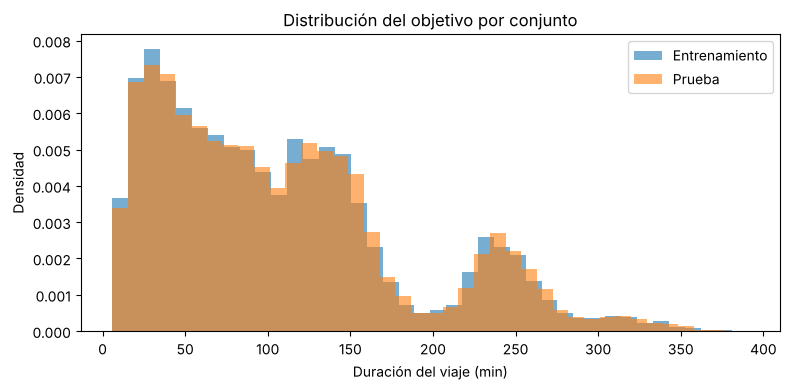

In [5]:
total = len(X_train) + len(X_test)
print(f"Total de viajes: {total:,}")
print(f"Entrenamiento: {len(X_train):,} ({len(X_train)/total:.0%}) | Prueba: {len(X_test):,} ({len(X_test)/total:.0%})")
print(f"Mediana del objetivo  train: {y_train.median()/60:.1f} min | test: {y_test.median()/60:.1f} min")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_train / 60, bins=40, alpha=0.6, density=True, label="Entrenamiento")
ax.hist(y_test / 60, bins=40, alpha=0.6, density=True, label="Prueba")
ax.set_xlabel("Duración del viaje (min)")
ax.set_ylabel("Densidad")
ax.set_title("Distribución del objetivo por conjunto")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Métrica de evaluación

El objetivo de negocio es decirle a operaciones **a qué hora llegará la unidad**. Por eso las métricas se reportan en **minutos**, que es como las entiende un despachador:

- **MAE (error absoluto medio), métrica principal.** Se lee directo como "en promedio, el ETA se equivoca ±X minutos". Es robusta ante viajes atípicos y es la que se usará para elegir entre modelos.
- **RMSE (raíz del error cuadrático medio), métrica secundaria.** Penaliza más los errores grandes. Para Feraltar un retraso de 40 minutos en un pickup de aeropuerto cuesta mucho más que cuatro errores de 10 minutos, así que el RMSE ayuda a detectar modelos que fallan feo en pocos viajes.
- **R², de apoyo.** Indica qué proporción de la variación de la duración explica el modelo; sirve para comparar, pero no tiene lectura operativa.

No se usan métricas porcentuales (MAPE) porque en viajes cortos un error pequeño en minutos se convierte en un porcentaje enorme y distorsiona la comparación.

La función `evaluar` calcula las tres métricas en entrenamiento y prueba para cada modelo y las guarda en `resultados`, que se usa en la tabla final.

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

resultados = []


def evaluar(nombre, modelo, X_tr, X_te):
    """Calcula MAE, RMSE (en minutos) y R² en entrenamiento y prueba."""
    fila = {"modelo": nombre}
    for conjunto, X_, y_ in [("train", X_tr, y_train), ("test", X_te, y_test)]:
        pred = modelo.predict(X_)
        fila[f"MAE_{conjunto}_min"] = mean_absolute_error(y_, pred) / 60
        fila[f"RMSE_{conjunto}_min"] = np.sqrt(mean_squared_error(y_, pred)) / 60
        fila[f"R2_{conjunto}"] = r2_score(y_, pred)
    resultados[:] = [r for r in resultados if r["modelo"] != nombre]
    resultados.append(fila)
    return pd.Series(fila).drop("modelo").astype(float).round(3)

## 6. Piso: modelo ingenuo (DummyRegressor)

Antes del baseline se entrena un modelo que **ignora todas las características** y siempre predice la mediana de la duración en entrenamiento. Se usa la mediana y no la media porque la distribución del objetivo tiene cola hacia la derecha (viajes largos) y la mediana minimiza el MAE.

Este modelo representa el desempeño "al azar" que menciona la actividad: si el baseline no lo supera con claridad, las características no contienen información útil para predecir la duración.

In [7]:
from sklearn.dummy import DummyRegressor

dummy = DummyRegressor(strategy="median").fit(X_train, y_train)
print(f"Predicción constante: {dummy.constant_[0][0] / 60:.1f} min para todos los viajes\n")
evaluar("Dummy (mediana)", dummy, X_train, X_test)

Predicción constante: 91.6 min para todos los viajes



MAE_train_min     59.367
RMSE_train_min    76.728
R2_train          -0.043
MAE_test_min      59.602
RMSE_test_min     77.223
R2_test           -0.050
dtype: float64

**Interpretación.** El modelo ingenuo predice 91.6 min para todos los viajes y se equivoca en promedio **±59.6 min** en prueba, con R² ligeramente negativo. Es el desempeño que se obtendría sin usar ninguna característica; cualquier modelo útil debe quedar muy por debajo de este error.

## 7. Referencia de negocio: regresión lineal simple

Feraltar no cuenta con un modelo previo de ETA: hoy la duración se estima con la regla operativa **"distancia entre velocidad promedio"**. Una regresión lineal con una sola variable, la distancia, es la versión aprendida de esa regla: el intercepto captura el tiempo fijo del viaje (salida, accesos, estacionamiento) y la pendiente equivale al inverso de una velocidad promedio.

Esta es la referencia de negocio: lo que se obtiene sin modelar hora, día ni zonas. El baseline deberá superarla para justificar el uso de más características.

In [8]:
from sklearn.linear_model import LinearRegression

COLUMNA_DISTANCIA = "distance_km"

simple = LinearRegression().fit(X_train[[COLUMNA_DISTANCIA]], y_train)
print(f"Intercepto: {simple.intercept_ / 60:.1f} min (duración estimada para la distancia promedio)")
print(f"Pendiente:  {simple.coef_[0] / 60:.1f} min por cada desviación estándar de distancia\n")
evaluar("Lineal simple (distancia)", simple, X_train[[COLUMNA_DISTANCIA]], X_test[[COLUMNA_DISTANCIA]])

Intercepto: 107.1 min (duración estimada para la distancia promedio)
Pendiente:  73.7 min por cada desviación estándar de distancia



MAE_train_min     11.458
RMSE_train_min    14.586
R2_train           0.962
MAE_test_min      11.272
RMSE_test_min     14.465
R2_test            0.963
dtype: float64

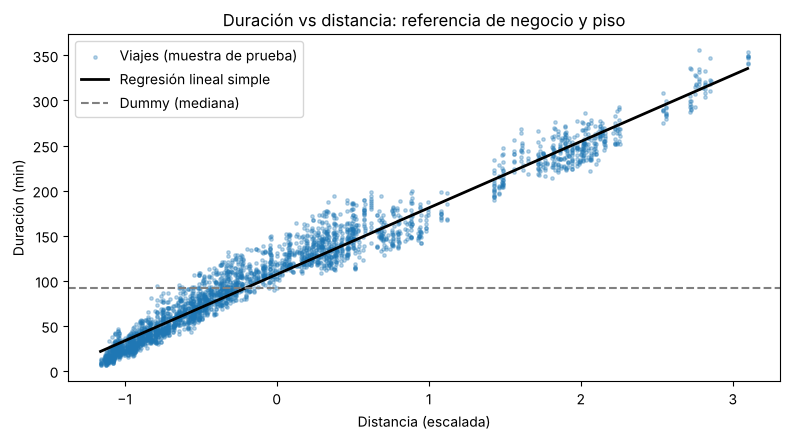

In [9]:
muestra = X_test.sample(min(3000, len(X_test)), random_state=SEMILLA).index
x_linea = np.linspace(X_test[COLUMNA_DISTANCIA].min(), X_test[COLUMNA_DISTANCIA].max(), 100)
y_linea = simple.predict(pd.DataFrame({COLUMNA_DISTANCIA: x_linea}))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(X_test.loc[muestra, COLUMNA_DISTANCIA], y_test.loc[muestra] / 60, s=6, alpha=0.3, label="Viajes (muestra de prueba)")
ax.plot(x_linea, y_linea / 60, color="black", linewidth=2, label="Regresión lineal simple")
ax.axhline(dummy.constant_[0][0] / 60, color="gray", linestyle="--", label="Dummy (mediana)")
ax.set_xlabel("Distancia (escalada)")
ax.set_ylabel("Duración (min)")
ax.set_title("Duración vs distancia: referencia de negocio y piso")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretación.** Con solo la distancia el error baja de ±59.6 a **±11.3 min** en prueba (R² de 0.96), una reducción del 81 %. Esto muestra que el problema es viable: la distancia explica casi toda la variación de la duración, y los grupos que se ven en el histograma de la sección 4 corresponden a rangos de distancia distintos más que a un comportamiento errático. Las métricas de entrenamiento y prueba son casi iguales, por lo que este modelo no sobreajusta.

El listón para el baseline queda en **11.3 min de MAE**: si al agregar hora, día y zonas no se baja de ahí, esas características no aportan valor suficiente para justificar un modelo más complejo.

## 8. Baseline: regresión lineal múltiple con Lasso

**¿Por qué una regresión lineal con regularización Lasso como baseline?**

- **Tipo de problema y de datos.** Es una regresión sobre datos **estructurados** (tabulares): una variable continua (distancia), variables cíclicas de hora y día, y zonas codificadas con one-hot. No hay texto ni imágenes que requieran otro tipo de modelo.
- **Cantidad de datos.** Con ~350 mil viajes de entrenamiento y 59 características, un modelo lineal entrena en segundos y permite usar validación cruzada sin costo, lo cual es deseable en un baseline.
- **Interpretabilidad.** Cada coeficiente se lee en minutos: cuánto suma o resta a la duración estar en cierta zona, o cada desviación estándar de distancia. Para operaciones de Feraltar esto es explicable, a diferencia de un modelo de caja negra.
- **Selección de características integrada (embedded).** La penalización L1 de Lasso lleva a cero los coeficientes de las características que no aportan, por lo que el propio modelo indica cuáles son irrelevantes. Esto responde directamente a la pregunta de la actividad sobre características irrelevantes.
- **Escala.** Las características continuas ya vienen estandarizadas desde el Avance 2, requisito para que la penalización trate a todas por igual.

La fuerza de la regularización (`alpha`) se elige con validación cruzada de 5 folds (`LassoCV`) sobre el conjunto de entrenamiento; el conjunto de prueba no se usa para elegirla.

In [10]:
from sklearn.linear_model import LassoCV

ALPHAS = np.logspace(-3, 2, 25)
lasso = LassoCV(alphas=ALPHAS, cv=5, random_state=SEMILLA, n_jobs=-1, max_iter=2000, tol=1e-3)
lasso.fit(X_train, y_train)

n_cero = int((lasso.coef_ == 0).sum())
print(f"Alpha elegido por validación cruzada: {lasso.alpha_:.5f}")
if np.isclose(lasso.alpha_, ALPHAS.min()) or np.isclose(lasso.alpha_, ALPHAS.max()):
    print("El alpha elegido es el más pequeño de la rejilla: la validación cruzada prefiere casi nada de regularización.")
print(f"Características usadas: {X_train.shape[1] - n_cero} de {X_train.shape[1]} ({n_cero} llevadas a cero)\n")
display(evaluar("Lasso (59 características)", lasso, X_train, X_test))

# Control: si la regularización casi no importa, una regresión lineal sin penalización debe dar lo mismo
ols = LinearRegression().fit(X_train, y_train)
mae_ols = mean_absolute_error(y_test, ols.predict(X_test)) / 60
mae_lasso = mean_absolute_error(y_test, lasso.predict(X_test)) / 60
print(f"\nControl: MAE en prueba sin regularización (OLS) {mae_ols:.3f} min vs Lasso {mae_lasso:.3f} min")

Alpha elegido por validación cruzada: 0.00100
El alpha elegido es el más pequeño de la rejilla: la validación cruzada prefiere casi nada de regularización.
Características usadas: 58 de 59 (1 llevadas a cero)



MAE_train_min      7.964
RMSE_train_min    10.331
R2_train           0.981
MAE_test_min       7.934
RMSE_test_min     10.273
R2_test            0.981
dtype: float64


Control: MAE en prueba sin regularización (OLS) 7.934 min vs Lasso 7.934 min


**Interpretación.** El baseline reduce el error a **±7.9 min** en prueba (R² de 0.98), contra ±11.3 min de la referencia de negocio y ±59.6 min del modelo ingenuo. Es decir, agregar hora, día y zonas a la distancia reduce el error en cerca de **30 %**, lo que justifica usar el conjunto completo de características del Avance 2.

La validación cruzada elige el `alpha` más pequeño de la rejilla. Esto no indica un problema de búsqueda sino que el modelo **casi no necesita regularización**: con cerca de 350 mil viajes y solo 59 características hay datos de sobra para estimar cada coeficiente, y el riesgo de sobreajuste es mínimo. El control con una regresión lineal sin penalización (OLS) da prácticamente el mismo MAE, por lo que ampliar la rejilla hacia valores menores no cambiaría el resultado. Aun así, Lasso conserva su valor como método de selección embebido: las características que lleva a cero son las que no aportan información.

## 9. Importancia de características

Se analiza la relevancia de las características con dos métodos complementarios:

1. **Coeficientes de Lasso (método embedded).** Indican el efecto de cada característica en minutos y cuáles fueron eliminadas. Ojo: no son directamente comparables entre tipos de variable. La distancia y las cíclicas están estandarizadas (el coeficiente es el efecto de una desviación estándar), mientras que cada zona es 0/1 y su coeficiente es la diferencia en minutos respecto a la zona de referencia que se eliminó en el one-hot.
2. **Importancia por permutación agrupada.** Para comparar en la misma escala, se desordena un grupo completo de columnas a la vez (por ejemplo, las 27 de zona de origen) y se mide cuánto empeora el MAE en prueba. Se agrupan porque permutar una sola columna del one-hot no tiene sentido: rompería la codificación.

Características llevadas a cero por Lasso:
['origin_zone_id_1']

Características usadas por grupo:
grupo
Distancia            1
Día de la semana     2
Hora del día         2
Zona de destino     27
Zona de origen      26


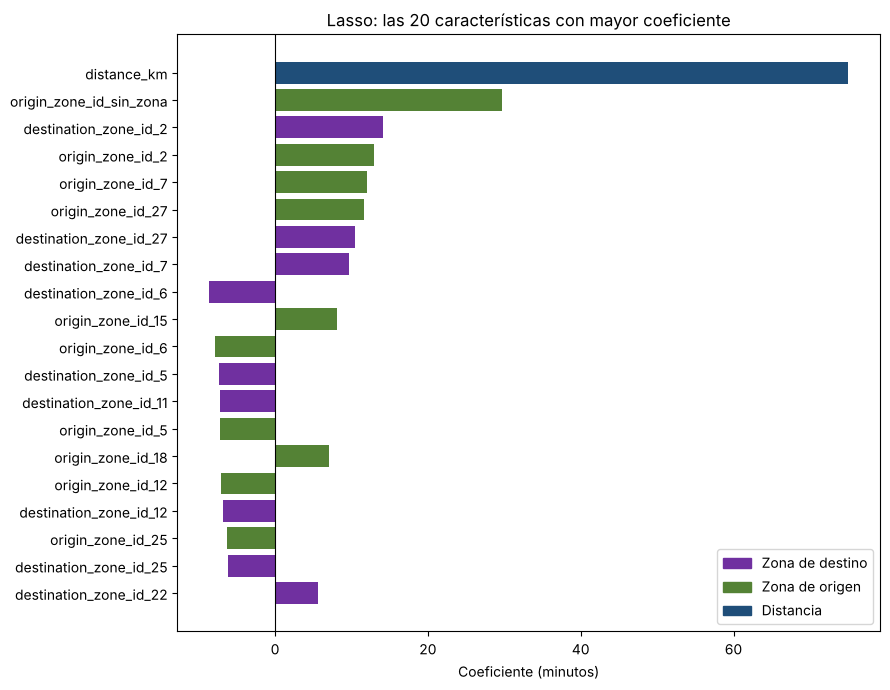

In [11]:
coefs = pd.Series(lasso.coef_ / 60, index=X_train.columns)


def grupo(col):
    if col == COLUMNA_DISTANCIA:
        return "Distancia"
    if col.startswith("hour_"):
        return "Hora del día"
    if col.startswith("dow_"):
        return "Día de la semana"
    if col.startswith("origin_zone"):
        return "Zona de origen"
    if col.startswith("destination_zone"):
        return "Zona de destino"
    return "Otra"


tabla_coefs = pd.DataFrame({"coef_min": coefs, "grupo": [grupo(c) for c in coefs.index]})
tabla_coefs["abs"] = tabla_coefs["coef_min"].abs()

print("Características llevadas a cero por Lasso:")
ceros = tabla_coefs.index[tabla_coefs["coef_min"] == 0].tolist()
print(ceros if ceros else "ninguna")
print("\nCaracterísticas usadas por grupo:")
print(tabla_coefs[tabla_coefs["coef_min"] != 0].groupby("grupo").size().to_string())

top = tabla_coefs.sort_values("abs", ascending=False).head(20).iloc[::-1]
colores = {"Distancia": "#1f4e79", "Hora del día": "#c55a11", "Día de la semana": "#7f6000",
           "Zona de origen": "#548235", "Zona de destino": "#7030a0", "Otra": "#808080"}

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top["coef_min"], color=[colores[g] for g in top["grupo"]])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coeficiente (minutos)")
ax.set_title("Lasso: las 20 características con mayor coeficiente")
manejadores = [plt.Rectangle((0, 0), 1, 1, color=colores[g]) for g in top["grupo"].unique()]
ax.legend(manejadores, top["grupo"].unique(), loc="lower right")
plt.tight_layout()
plt.show()

MAE de referencia en prueba: 7.93 min

                  aumento_MAE_min  desv
Distancia                   73.63  0.17
Zona de origen               2.41  0.02
Zona de destino              2.22  0.01
Hora del día                 2.15  0.01
Día de la semana             1.10  0.01


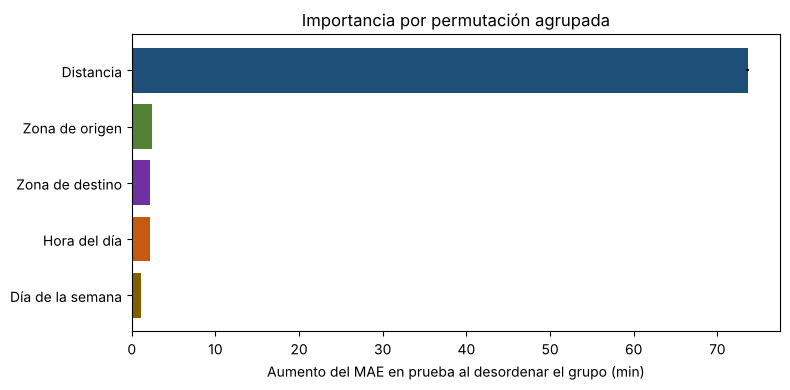

In [12]:
grupos = tabla_coefs.groupby("grupo").groups
rng = np.random.default_rng(SEMILLA)
mae_base = mean_absolute_error(y_test, lasso.predict(X_test)) / 60
REPETICIONES = 5

importancia = {}
for nombre_grupo, columnas in grupos.items():
    columnas = list(columnas)
    aumentos = []
    for _ in range(REPETICIONES):
        X_perm = X_test.copy()
        orden = rng.permutation(len(X_perm))
        X_perm[columnas] = X_perm[columnas].values[orden]
        aumentos.append(mean_absolute_error(y_test, lasso.predict(X_perm)) / 60 - mae_base)
    importancia[nombre_grupo] = (np.mean(aumentos), np.std(aumentos))

imp = pd.DataFrame(importancia, index=["aumento_MAE_min", "desv"]).T.sort_values("aumento_MAE_min")
print(f"MAE de referencia en prueba: {mae_base:.2f} min\n")
print(imp.round(2).iloc[::-1].to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(imp.index, imp["aumento_MAE_min"], xerr=imp["desv"], color=[colores[g] for g in imp.index])
ax.set_xlabel("Aumento del MAE en prueba al desordenar el grupo (min)")
ax.set_title("Importancia por permutación agrupada")
plt.tight_layout()
plt.show()

**Interpretación.** Ambos métodos coinciden en que la **distancia es por mucho la característica más importante**: al desordenarla el MAE sube más de 70 min, prácticamente al nivel del modelo ingenuo.

Las demás características tienen un efecto pequeño pero real. Desordenar las zonas de origen, las de destino o la hora sube el MAE alrededor de 2 min cada una, y el día de la semana alrededor de 1 min. Por separado parecen marginales, pero en conjunto son la diferencia entre los ±11.3 min de la referencia de negocio y los ±7.9 min del baseline. Los coeficientes de zona se leen como correcciones de entre 5 y 15 min, positivas o negativas, sobre lo que indicaría la distancia; esto es consistente con zonas de acceso lento (tráfico urbano, casetas, caminos internos de los desarrollos) frente a tramos de carretera libre.

Lasso solo lleva a cero una columna de zona (`origin_zone_id_1`), por lo que no se encontraron características irrelevantes que convenga eliminar: todas aportan, aunque sea poco. Un caso a tratar con cautela es `origin_zone_id_sin_zona`: su coeficiente es de los más grandes, pero proviene de solo 7 viajes, así que se interpreta como ruido y no como un efecto real.

## 10. Sub/sobreajuste

Se revisan cuatro señales:

1. **Métricas de entrenamiento vs prueba.** Si el error en prueba es mucho mayor que en entrenamiento hay sobreajuste; si ambos son altos y parecidos, subajuste.
2. **Validación cruzada de 5 folds.** Una desviación estándar pequeña del MAE entre folds indica que el desempeño es estable y no depende de la partición.
3. **Curva de aprendizaje.** Si las curvas de entrenamiento y validación convergen a un error parecido, agregar más datos ya no ayuda y el límite está en la capacidad del modelo.
4. **Gráficas de residuos.** Un patrón en los residuos (por ejemplo, curvatura respecto a la distancia) indica que el modelo no captura una relación no lineal: es la huella típica del subajuste en un modelo lineal.

In [13]:
tabla_ajuste = pd.DataFrame(resultados).set_index("modelo")
tabla_ajuste["brecha_MAE_min"] = tabla_ajuste["MAE_test_min"] - tabla_ajuste["MAE_train_min"]
tabla_ajuste[["MAE_train_min", "MAE_test_min", "brecha_MAE_min", "RMSE_train_min", "RMSE_test_min", "R2_train", "R2_test"]].round(3)

,MAE_train_min,MAE_test_min,brecha_MAE_min,RMSE_train_min,RMSE_test_min,R2_train,R2_test
modelo,,,,,,,
Dummy (mediana),59.367,59.602,0.235,76.728,77.223,-0.043,-0.050
Lineal simple (distancia),11.458,11.272,-0.187,14.586,14.465,0.962,0.963
Lasso (59 características),7.964,7.934,-0.030,10.331,10.273,0.981,0.981


In [14]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold, cross_val_score, learning_curve

lasso_fijo = Lasso(alpha=lasso.alpha_, max_iter=2000, tol=1e-3)
kfold = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

mae_cv = -cross_val_score(lasso_fijo, X_train, y_train, cv=kfold, scoring="neg_mean_absolute_error", n_jobs=-1) / 60
print("MAE por fold (min):", np.round(mae_cv, 3))
print(f"MAE validación cruzada: {mae_cv.mean():.3f} ± {mae_cv.std():.3f} min")

MAE por fold (min): [7.953 7.963 7.986 7.973 7.95 ]
MAE validación cruzada: 7.965 ± 0.013 min


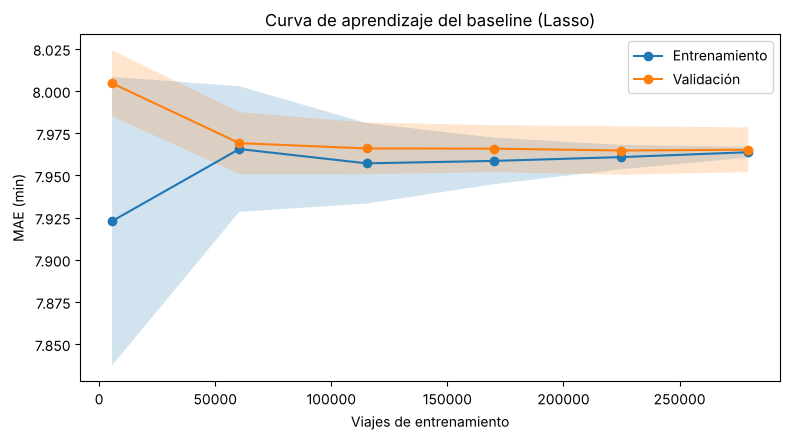

Tamaño | MAE entrenamiento | MAE validación
   5,591 |    7.923 |    8.005
  60,384 |    7.966 |    7.969
 115,177 |    7.957 |    7.966
 169,970 |    7.959 |    7.966
 224,763 |    7.961 |    7.965
 279,556 |    7.964 |    7.965


In [15]:
tamanos, mae_tr, mae_val = learning_curve(
    lasso_fijo, X_train, y_train, cv=kfold, scoring="neg_mean_absolute_error",
    train_sizes=np.linspace(0.02, 1.0, 6), n_jobs=1, shuffle=True, random_state=SEMILLA,
)
mae_tr, mae_val = -mae_tr / 60, -mae_val / 60

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tamanos, mae_tr.mean(axis=1), "o-", label="Entrenamiento")
ax.fill_between(tamanos, mae_tr.mean(axis=1) - mae_tr.std(axis=1), mae_tr.mean(axis=1) + mae_tr.std(axis=1), alpha=0.2)
ax.plot(tamanos, mae_val.mean(axis=1), "o-", label="Validación")
ax.fill_between(tamanos, mae_val.mean(axis=1) - mae_val.std(axis=1), mae_val.mean(axis=1) + mae_val.std(axis=1), alpha=0.2)
ax.set_xlabel("Viajes de entrenamiento")
ax.set_ylabel("MAE (min)")
ax.set_title("Curva de aprendizaje del baseline (Lasso)")
ax.legend()
plt.tight_layout()
plt.show()

print("Tamaño | MAE entrenamiento | MAE validación")
for t, a, b in zip(tamanos, mae_tr.mean(axis=1), mae_val.mean(axis=1)):
    print(f"{t:>8,} | {a:>8.3f} | {b:>8.3f}")

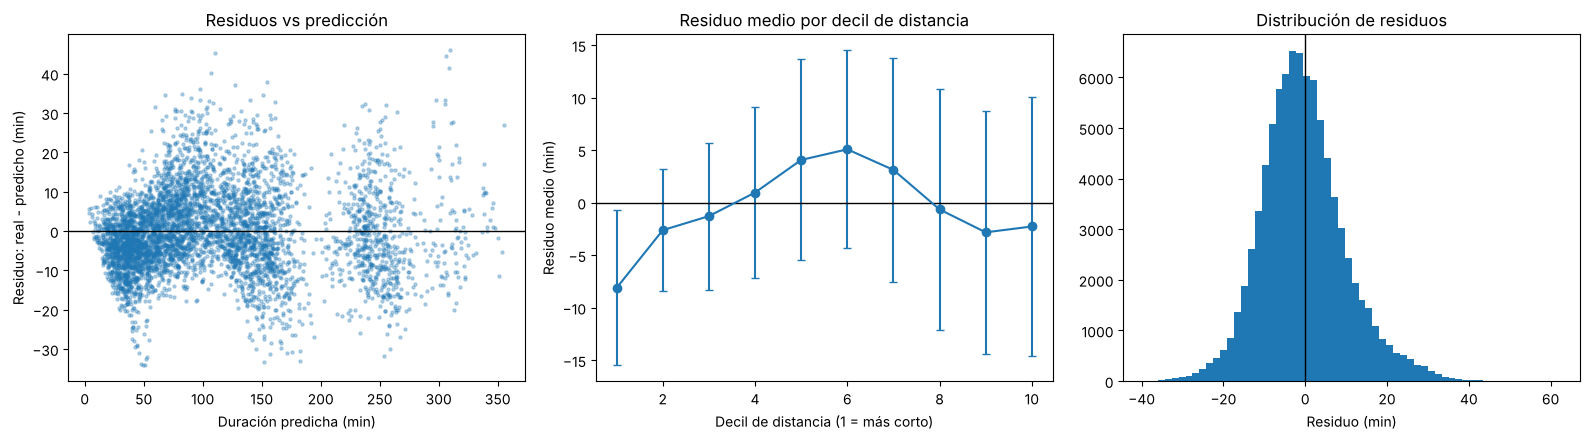

Residuo medio: -0.44 min | mediana: -1.21 min
Residuo medio por decil de distancia (min):
0   -8.11
1   -2.62
2   -1.28
3    0.96
4    4.07
5    5.08
6    3.12
7   -0.65
8   -2.83
9   -2.27


In [16]:
pred_test = lasso.predict(X_test)
residuos = (y_test - pred_test) / 60
idx = X_test.sample(min(5000, len(X_test)), random_state=SEMILLA).index
pos = X_test.index.get_indexer(idx)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].scatter(pred_test[pos] / 60, residuos.iloc[pos], s=5, alpha=0.3)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xlabel("Duración predicha (min)")
axes[0].set_ylabel("Residuo: real - predicho (min)")
axes[0].set_title("Residuos vs predicción")

deciles = pd.qcut(X_test[COLUMNA_DISTANCIA], 10, labels=False, duplicates="drop")
por_decil = residuos.groupby(deciles.values).agg(["mean", "std"])
axes[1].errorbar(por_decil.index + 1, por_decil["mean"], yerr=por_decil["std"], fmt="o-", capsize=3)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel("Decil de distancia (1 = más corto)")
axes[1].set_ylabel("Residuo medio (min)")
axes[1].set_title("Residuo medio por decil de distancia")

axes[2].hist(residuos, bins=60)
axes[2].axvline(0, color="black", linewidth=1)
axes[2].set_xlabel("Residuo (min)")
axes[2].set_title("Distribución de residuos")

plt.tight_layout()
plt.show()

print(f"Residuo medio: {residuos.mean():.2f} min | mediana: {residuos.median():.2f} min")
print("Residuo medio por decil de distancia (min):")
print(por_decil["mean"].round(2).to_string())

**Interpretación.** Las cuatro señales apuntan en la misma dirección: el baseline **no sobreajusta, pero sí subajusta ligeramente**.

1. **Entrenamiento vs prueba.** La brecha de MAE es prácticamente cero en los tres modelos (−0.03 min en el Lasso). El modelo generaliza igual de bien a viajes que no vio.
2. **Validación cruzada.** El MAE por fold es de 7.97 ± 0.01 min. El desempeño es muy estable y no depende de cómo se parte el conjunto.
3. **Curva de aprendizaje.** Desde unos 60 mil viajes las curvas de entrenamiento y validación se juntan en ~7.97 min y se quedan planas. **Más datos ya no ayudan**: el límite está en la capacidad del modelo lineal, no en la cantidad de información.
4. **Residuos.** La distribución está centrada cerca de cero (residuo medio −0.4 min), pero el residuo medio por decil de distancia muestra un **patrón sistemático**: el modelo sobreestima los viajes más cortos (unos 8 min en el primer decil), subestima los de distancia media (4 a 5 min en los deciles 5 y 6) y vuelve a sobreestimar los más largos. Una recta no captura la curvatura real entre distancia y duración, que cambia según el tipo de tramo (ciudad, zona hotelera, carretera).

Este subajuste es esperado en un modelo lineal y es justamente lo que deben resolver los modelos del siguiente avance: algoritmos no lineales como árboles de decisión, Random Forest o gradient boosting (XGBoost, LightGBM), que pueden modelar la curvatura con la distancia y las interacciones entre zona y hora sin especificarlas a mano.

## 11. Desempeño mínimo y comparación

**Situación actual (histórico vs no existe).** Feraltar no tiene un modelo de ETA previo ni registros históricos de error contra los cuales comparar: hoy el tiempo de un traslado se estima con la experiencia del despachador y la regla "distancia entre velocidad promedio". Por eso el desempeño mínimo se define en dos niveles:

1. **Mínimo técnico:** superar a la referencia de negocio de la sección 7 (regresión lineal simple con distancia, ±11.3 min). Si un modelo no la supera, la complejidad adicional no se justifica.
2. **Mínimo operativo propuesto:** que la mayoría de los viajes queden dentro de una tolerancia que operaciones pueda usar para avisar al cliente y reasignar unidades. Se propone medir el porcentaje de viajes con error menor a **±10 min** y **±15 min**. Este umbral es una propuesta del equipo y debe validarse con la gerencia de operaciones de Feraltar.

La tabla compara los tres modelos en el conjunto de prueba con todas las métricas.

In [17]:
predicciones = {
    "Dummy (mediana)": dummy.predict(X_test),
    "Lineal simple (distancia)": simple.predict(X_test[[COLUMNA_DISTANCIA]]),
    "Lasso (59 características)": lasso.predict(X_test),
}

filas = []
for nombre, pred in predicciones.items():
    error = np.abs(y_test.values - pred) / 60
    filas.append({
        "modelo": nombre,
        "MAE_min": error.mean(),
        "RMSE_min": np.sqrt((error ** 2).mean()),
        "R2": r2_score(y_test, pred),
        "dentro_10min_%": (error <= 10).mean() * 100,
        "dentro_15min_%": (error <= 15).mean() * 100,
    })
comparacion = pd.DataFrame(filas).set_index("modelo")
referencia = comparacion.loc["Lineal simple (distancia)", "MAE_min"]
comparacion["mejora_vs_referencia_%"] = (1 - comparacion["MAE_min"] / referencia) * 100
comparacion.round(2)

,MAE_min,RMSE_min,R2,dentro_10min_%,dentro_15min_%,mejora_vs_referencia_%
modelo,,,,,,
Dummy (mediana),59.60,77.22,-0.05,9.63,14.22,-428.78
Lineal simple (distancia),11.27,14.47,0.96,53.29,74.11,0.00
Lasso (59 características),7.93,10.27,0.98,70.30,86.67,29.61


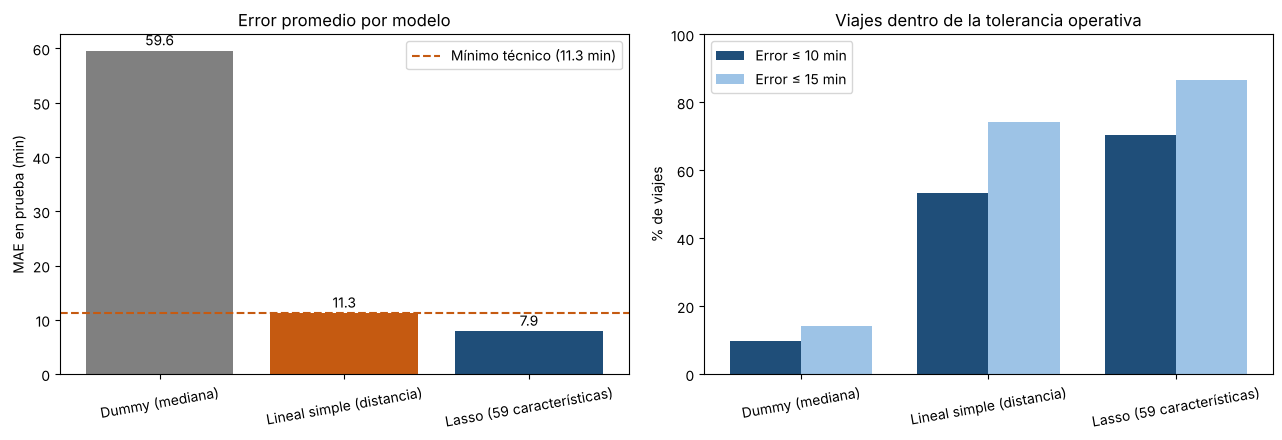

¿El baseline supera el mínimo técnico? Sí


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colores_modelo = ["#808080", "#c55a11", "#1f4e79"]

axes[0].bar(comparacion.index, comparacion["MAE_min"], color=colores_modelo)
axes[0].axhline(referencia, color="#c55a11", linestyle="--", label=f"Mínimo técnico ({referencia:.1f} min)")
axes[0].set_ylabel("MAE en prueba (min)")
axes[0].set_title("Error promedio por modelo")
axes[0].legend()
for k, v in enumerate(comparacion["MAE_min"]):
    axes[0].text(k, v + 1, f"{v:.1f}", ha="center")

ancho = 0.38
x = np.arange(len(comparacion))
axes[1].bar(x - ancho / 2, comparacion["dentro_10min_%"], ancho, label="Error ≤ 10 min", color="#1f4e79")
axes[1].bar(x + ancho / 2, comparacion["dentro_15min_%"], ancho, label="Error ≤ 15 min", color="#9dc3e6")
axes[1].set_xticks(x)
axes[1].set_xticklabels(comparacion.index)
axes[1].set_ylabel("% de viajes")
axes[1].set_ylim(0, 100)
axes[1].set_title("Viajes dentro de la tolerancia operativa")
axes[1].legend()

for ax in axes:
    ax.tick_params(axis="x", labelrotation=10)
plt.tight_layout()
plt.show()

supera = comparacion.loc["Lasso (59 características)", "MAE_min"] < referencia
supera_txt = "Sí" if supera else "No"
print(f"¿El baseline supera el mínimo técnico? {supera_txt}")

**Interpretación.** El baseline **cumple el mínimo técnico**: su MAE de 7.9 min es 29.6 % menor que el de la referencia de negocio (11.3 min).

En términos operativos, el cambio también es claro:

| Modelo | Viajes con error ≤ 10 min | Viajes con error ≤ 15 min |
|---|---|---|
| Dummy (mediana) | 9.6 % | 14.2 % |
| Lineal simple (distancia) | 53.3 % | 74.1 % |
| Lasso (baseline) | **70.3 %** | **86.7 %** |

Con el baseline, 7 de cada 10 traslados quedarían dentro de ±10 min y casi 9 de cada 10 dentro de ±15 min. Sin embargo, todavía **13 % de los viajes se desvía más de 15 min**, que es justamente el tipo de error que más afecta un pickup de aeropuerto. Este baseline queda como el desempeño mínimo que deberán superar los modelos del siguiente avance, tanto en MAE como en el porcentaje de viajes dentro de tolerancia.

## 12. Conclusiones

**Selección del modelo.** Se eligió como baseline una regresión lineal múltiple con Lasso, ya que el problema es de regresión para predecir una variable continua (duración del viaje). Este modelo es rápido de entrenar e interpretable (se pueden leer los coeficientes usados). Además, para dar contexto, se compararon dos modelos simples: un regresor ingenuo (DummyRegressor) como piso y una regresión lineal simple con distancia como referencia de negocio, equivalente a la regla operativa actual de Feraltar. Las métricas fueron MAE (principal, en minutos), RMSE (penaliza errores grandes, clave porque un retraso de 40 min es mucho más grave que uno de 10) y R².

**Resultados.** Cada uno de los tres modelos fue entrenado y probado con la misma partición de entrenamiento y prueba (mantenida desde el Avance 2):
- Regresor ingenuo (DummyRegressor): obtuvo un MAE de ±59.6 min en prueba, lo que lo hace inútil para el negocio, donde se busca el menor margen de retraso posible en cada viaje.
- Regresión lineal simple (referencia de negocio): obtuvo un MAE de ±11.3 min (R² = 0.96), una reducción de 81 % respecto al regresor ingenuo. Esto indica que la distancia explica la mayor parte de la variación de la duración.
- Regresión lineal múltiple con Lasso (baseline): obtuvo un MAE de ±7.9 min (R² = 0.98), 30 % menos error que la referencia de negocio. Con este modelo, 70 % de los viajes queda dentro de ±10 min y 87 % dentro de ±15 min, pero 13 % aún se desvía más de 15 min. Este baseline es el desempeño mínimo que deberán superar los modelos del siguiente avance.

**Importancia de las características.** Se analizaron los coeficientes de Lasso y la importancia por permutación agrupada. La distancia es la característica más importante con amplio margen (desordenarla sube el MAE más de 70 min). Las zonas de origen, destino y la hora aportan aproximadamente 2 min cada una, y el día de la semana cerca de 1 min. Son correcciones pequeñas, pero explican la diferencia entre el modelo simple y el baseline, además, son importantes para minimizar el error del modelo.
  
**Aseguramiento de calidad.** No se detectaron señales de sobreajuste (brecha train/test ≈ 0; MAE en validación cruzada de 7.97 ± 0.01 min). Sin embargo, se observa un ligero subajuste: los residuos por decil de distancia muestran que el modelo sobreestima los viajes cortos (unos 8 min), subestima los de distancia media (4 a 5 min) y vuelve a sobreestimar los más largos. Además, la curva de aprendizaje se aplana desde ~60 mil viajes, por lo que el límite está en la capacidad del modelo lineal y no en la cantidad de datos.

**Riesgos.** Los datos usados hasta ahora son sintéticos. Si bien muestran que el problema es abordable con la metodología propuesta, es posible que los datos reales presenten diferencias significativas y sistemáticas. Por ello, el análisis de importancia de características debe repetirse cuando se cuente con una base de datos reales suficientemente grande. Además, la partición fue aleatoria y no temporal, por lo que habrá que evaluar con viajes posteriores a los de entrenamiento.

**Siguientes pasos.** Será importante comparar el desempeño de diferentes modelos como SVM, XGBoost y Random Forest con el objetivo de superar el MAE de 7.9 min y el 70% de los viajes dentro de ±10 min, poniendo especial atención en resolver el problema de subajuste observado en el desempeño de nuestro modelo baseline. 

Además, al tener datos reales, se deberán asignar la zona de destino y origen usando sus coordenadas GPS (utilizando un método de point-in-polygon) para validar el modelo con datos reales. 

## 13. Bibliografía

- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
- Visengeriyeva, L., Kammer, A., Bär, I., Kniesz, A., y Plöd, M. (2023). *CRISP-ML(Q). The ML Lifecycle Process*. MLOps. INNOQ. https://ml-ops.org/content/crisp-ml